In [13]:
from pathlib import Path as _dataset_Path
import csv as _dataset_csv
import fnmatch as _dataset_fnmatch
import shutil as _dataset_shutil
import zipfile as _dataset_zipfile

_dataset_script_dir = _dataset_Path.cwd().resolve()
_dataset_search_dirs = []
for _dataset_dir in (_dataset_script_dir, _dataset_Path.cwd().resolve()):
    if _dataset_dir not in _dataset_search_dirs:
        _dataset_search_dirs.append(_dataset_dir)

_dataset_requirements = {
    "opera_dataset_1w_10min.csv": "opera_dataset_1w_10min*.csv",
    "opera_dataset_3w_90min.csv": "opera_dataset_3w_90min*.csv",
}


def _dataset_has_required_columns(_dataset_path):
    try:
        with _dataset_path.open("r", encoding="utf-8-sig", newline="") as _dataset_handle:
            _dataset_header = [str(x).strip() for x in next(_dataset_csv.reader(_dataset_handle), [])]
        return "timestamp" in _dataset_header and "Pa1" in _dataset_header
    except (OSError, UnicodeError, _dataset_csv.Error):
        return False


def _dataset_find_candidates(_dataset_glob_pattern):
    _dataset_candidates = []
    _dataset_seen = set()
    for _dataset_dir in _dataset_search_dirs:
        if not _dataset_dir.exists():
            continue
        # Search the working directory and one level of child folders.
        _dataset_locations = [_dataset_dir]
        try:
            _dataset_locations.extend(p for p in _dataset_dir.iterdir() if p.is_dir() and p.name not in {".git", "drive"})
        except OSError:
            pass
        for _dataset_location in _dataset_locations:
            try:
                _dataset_matches = _dataset_location.glob(_dataset_glob_pattern)
                for _dataset_candidate in _dataset_matches:
                    if not _dataset_candidate.is_file():
                        continue
                    _dataset_resolved = _dataset_candidate.resolve()
                    if _dataset_resolved in _dataset_seen:
                        continue
                    _dataset_seen.add(_dataset_resolved)
                    if _dataset_has_required_columns(_dataset_candidate):
                        _dataset_candidates.append(_dataset_candidate)
            except OSError:
                continue
    return _dataset_candidates


def _dataset_process_uploaded_zip(_dataset_zip_path):
    # Extract only the two named OPERA CSVs, avoiding arbitrary archive paths.
    try:
        with _dataset_zipfile.ZipFile(_dataset_zip_path, "r") as _dataset_archive:
            for _dataset_info in _dataset_archive.infolist():
                if _dataset_info.is_dir():
                    continue
                _dataset_basename = _dataset_Path(_dataset_info.filename).name
                _dataset_basename_lower = _dataset_basename.lower()
                if not any(
                    _dataset_fnmatch.fnmatchcase(_dataset_basename_lower, _dataset_pattern.lower())
                    for _dataset_pattern in _dataset_requirements.values()
                ):
                    continue
                _dataset_bytes = _dataset_archive.read(_dataset_info)
                _dataset_destination = _dataset_script_dir / _dataset_basename
                _dataset_destination.write_bytes(_dataset_bytes)
                print(f"Dataset upload: extracted {_dataset_basename}")
    except _dataset_zipfile.BadZipFile:
        print(f"Dataset upload: {_dataset_zip_path.name} is not a readable ZIP archive; ignoring it.")


def _dataset_ensure_uploads_if_needed():
    _dataset_missing = [
        _dataset_expected
        for _dataset_expected, _dataset_pattern in _dataset_requirements.items()
        if not _dataset_find_candidates(_dataset_pattern)
    ]
    if not _dataset_missing:
        return

    try:
        from google.colab import files as _dataset_colab_files
    except ImportError:
        return

    print(
        "Required OPERA CSVs are not present in this runtime."
    )
    _dataset_uploaded = _dataset_colab_files.upload()
    for _dataset_uploaded_name in _dataset_uploaded:
        _dataset_uploaded_path = _dataset_script_dir / _dataset_Path(_dataset_uploaded_name).name
        if _dataset_uploaded_path.suffix.lower() == ".zip":
            _dataset_process_uploaded_zip(_dataset_uploaded_path)

    _dataset_still_missing = [
        _dataset_expected
        for _dataset_expected, _dataset_pattern in _dataset_requirements.items()
        if not _dataset_find_candidates(_dataset_pattern)
    ]
    if _dataset_still_missing:
        raise FileNotFoundError(
            "The following required OPERA dataset(s) are still missing or do not have the "
            "required 'timestamp' and 'Pa1' columns: " + ", ".join(_dataset_still_missing) + ". "

        )


def _dataset_prepare_expected_name(_dataset_expected_name, _dataset_glob_pattern):
    _dataset_destination = _dataset_script_dir / _dataset_expected_name
    _dataset_candidates = _dataset_find_candidates(_dataset_glob_pattern)
    if not _dataset_candidates:
        raise FileNotFoundError(
            f"Could not find a valid CSV for {_dataset_expected_name}. "
            "Run the dataset-setup cell and upload both required OPERA CSVs."
        )

    # Prefer the exact canonical filename; otherwise use the most recently uploaded match.
    _dataset_candidates.sort(
        key=lambda p: (p.name == _dataset_expected_name, p.stat().st_mtime), reverse=True
    )
    _dataset_source = _dataset_candidates[0]
    if _dataset_source.resolve() != _dataset_destination.resolve():
        _dataset_destination.parent.mkdir(parents=True, exist_ok=True)
        _dataset_shutil.copy2(_dataset_source, _dataset_destination)
        print(f"Dataset filename setup: using {_dataset_source.name} as {_dataset_expected_name}")
    else:
        print(f"Dataset filename setup: validated {_dataset_expected_name}")
    return _dataset_destination


_dataset_ensure_uploads_if_needed()
_dataset_prepare_expected_name(
    "opera_dataset_1w_10min.csv", _dataset_requirements["opera_dataset_1w_10min.csv"]
)
_dataset_prepare_expected_name(
    "opera_dataset_3w_90min.csv", _dataset_requirements["opera_dataset_3w_90min.csv"]
)


Dataset filename setup: validated opera_dataset_1w_10min.csv
Dataset filename setup: validated opera_dataset_3w_90min.csv


PosixPath('/content/opera_dataset_3w_90min.csv')

In [24]:
#!/usr/bin/env python3
"""LightGBM random 80/20 holdout for OPERA PV nowcasting.

Reference metrics :
R2=0.9983, MAE=173.47 W, RMSE=360.13 W.
"""

from __future__ import annotations

import argparse
import json
import os
import re
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from lightgbm import LGBMRegressor, early_stopping, log_evaluation

# --- Constants & Configuration Defaults ---
SEED = 42
TARGET = "Pa1"  # The target variable representing actual active power generation
N_JOBS = min(4, os.cpu_count() or 1)
PAPER = {"r2": 0.9983, "mae_w": 173.47, "rmse_w": 360.13}

try:
    ROOT = Path(__file__).resolve().parent
except NameError:
    ROOT = Path(".").resolve()

DEFAULT_10M = ROOT / "opera_dataset_1w_10min.csv"
DEFAULT_90M = ROOT / "opera_dataset_3w_90min.csv"
DEFAULT_OUT = ROOT / "pv_lightgbm_minimal_results"

# LGBM hyperparameter setups targeting regression (L2) and absolute error (L1)
CONFIGS = {
    "LGBM_leaf31": dict(
        objective="regression", n_estimators=1000, learning_rate=0.025,
        num_leaves=31, max_depth=-1, min_child_samples=25,
        subsample=0.90, subsample_freq=1, colsample_bytree=0.90,
        reg_lambda=3.0, reg_alpha=0.05,
    ),
    "LGBM_l1_leaf31": dict(
        objective="regression_l1", n_estimators=1000, learning_rate=0.025,
        num_leaves=31, max_depth=-1, min_child_samples=25,
        subsample=0.90, subsample_freq=1, colsample_bytree=0.90,
        reg_lambda=3.0, reg_alpha=0.05,
    ),
}

# Prefixes representing valid meteorological/environmental features
ENV_PREFIXES = (
    "rad", "irradiance", "globalirradiance",
    "tam", "tamb", "ambienttemp",
    "tmod", "moduletemp", "tempmod", "tempmodule",
)
ENV_SUMMARY_STARTS = ("avg", "mean", "min", "max", "std", "median", "var", "sum", "p10", "p90")

# Markers designating direct targets or leaking variables that must be filtered out
FORBIDDEN_MARKERS = (
    "pa1", "power", "current", "voltage", "output", "generation",
    "production", "energy", "target", "label", "ampere", "watt", "volt",
)


def normalise_name(name: str) -> str:
    """Standardizes feature names by lowering case and stripping non-alphanumeric chars."""
    return re.sub(r"[^a-z0-9]", "", str(name).lower())


def read_frame(path: Path) -> pd.DataFrame:
    """Reads and cleans the source CSV files.

    Ensures standard datetimes, coerces target values to numeric formats, removes null
    measurements, and guarantees that there are no duplicate timestamps.
    """
    if not path.exists():
        raise FileNotFoundError(f"CSV not found: {path}")
    frame = pd.read_csv(path)
    if "timestamp" not in frame.columns or TARGET not in frame.columns:
        raise ValueError(f"{path.name} must contain 'timestamp' and '{TARGET}'.")

    frame["timestamp"] = pd.to_datetime(frame["timestamp"], errors="coerce", utc=True)
    frame[TARGET] = pd.to_numeric(frame[TARGET], errors="coerce")

    # Keep records with both valid timestamps and valid target measurements
    valid = frame["timestamp"].notna() & np.isfinite(frame[TARGET].to_numpy(dtype=float))
    removed = int((~valid).sum())
    frame = frame.loc[valid].copy().sort_values("timestamp").reset_index(drop=True)

    if removed:
        print(f"{path.name}: removed {removed} row(s) with invalid timestamp/target.")
    if frame["timestamp"].duplicated().any():
        examples = frame.loc[frame["timestamp"].duplicated(keep=False), "timestamp"].head(5).astype(str).tolist()
        raise ValueError(f"Duplicate timestamps in {path.name}: {examples}")
    if len(frame) < 100:
        raise ValueError(f"Too few valid rows in {path.name}: {len(frame)}")
    return frame


def load_and_align(path_10m: Path, path_90m: Path) -> pd.DataFrame:
    """Validates target consistency and aligns the 10-minute and 90-minute datasets.

    Rejects records that do not contain a complete, consecutive trailing historical context.
    """
    ten = read_frame(path_10m)
    ninety = read_frame(path_90m)

    # Find overlapping intervals
    overlap = ninety[["timestamp", TARGET]].merge(
        ten[["timestamp", TARGET]], on="timestamp", how="inner", suffixes=("_90m", "_10m")
    )
    if overlap.empty:
        raise ValueError("The 10-minute and 90-minute files have no matching timestamps.")

    # Cross-verify target coherence
    diff = np.abs(overlap[f"{TARGET}_90m"].to_numpy(float) - overlap[f"{TARGET}_10m"].to_numpy(float))
    max_diff = float(np.max(diff))
    if max_diff > 1e-3:
        raise ValueError(f"Pa1 differs between files at matching timestamps (max difference {max_diff:g} W).")

    # Maintain lookback safety: verify consecutive trailing 10-minute records
    base_ts = pd.DatetimeIndex(ten["timestamp"])
    base_positions = {stamp: i for i, stamp in enumerate(base_ts)}
    step_ns = pd.Timedelta(minutes=10).value
    keep = []
    for i, stamp in enumerate(ninety["timestamp"]):
        pos = base_positions.get(stamp)
        if pos is None or pos < 8:
            continue
        history = base_ts.asi8[pos - 8:pos + 1]
        if len(history) == 9 and np.all(np.diff(history) == step_ns):
            keep.append(i)

    data = ninety.iloc[keep].reset_index(drop=True)
    if data.empty:
        raise ValueError("No rows have complete trailing 10-minute history.")
    print(f"Target-alignment check passed: {len(overlap):,} matching timestamps; max difference={max_diff:g} W.")
    print(f"Rows retained after complete-history check: {len(data):,}")
    return data


def select_environmental_features(data: pd.DataFrame) -> pd.DataFrame:
    """Extracts pure meteorological predictors while filtering out targets or power labels."""
    selected = []
    for col in data.columns:
        if col in {"timestamp", TARGET}:
            continue
        name = normalise_name(col)
        if not name or any(marker in name for marker in FORBIDDEN_MARKERS):
            continue
        is_env = name.startswith(ENV_PREFIXES)
        # Include Global Irradiance (GI) parameters corresponding to paper features
        is_gi = name == "gi" or (name.startswith("gi") and name[2:].startswith(ENV_SUMMARY_STARTS))
        if is_env or is_gi:
            selected.append(col)

    if not selected:
        raise ValueError(f"No environmental predictors found. Available columns: {list(data.columns)}")
    X = data[selected].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    all_missing = [col for col in X.columns if X[col].isna().all()]
    if all_missing:
        X = X.drop(columns=all_missing)
    if X.shape[1] == 0:
        raise ValueError("No usable environmental predictors remain after numeric conversion.")
    print(f"Environmental predictors ({X.shape[1]}): {list(X.columns)}")
    return X


def build_feature_sets(X_raw: pd.DataFrame) -> dict[str, pd.DataFrame]:
    """Generates raw and physically engineered feature sets for modeling."""
    sets = {"env_only": X_raw.copy()}
    X = X_raw.copy()
    lookup = {normalise_name(c): c for c in X.columns}

    def find(*aliases: str) -> str | None:
        return next((lookup[normalise_name(a)] for a in aliases if normalise_name(a) in lookup), None)

    # Resolve primary columns across historical and current windows
    rad = find("Rad_avg", "Rad_mean", "GI_avg", "Irradiance_avg")
    tmod = find("Tmod_avg", "Tmodule_avg", "ModuleTemp_avg")
    tamb = find("Tamb_avg", "Tam_avg", "AmbientTemp_avg")
    rad_w2 = find("Rad_avg_w2", "Rad_mean_w2", "GI_avg_w2")
    rad_w3 = find("Rad_avg_w3", "Rad_mean_w3", "GI_avg_w3")

    # Build physical domain interactions (e.g. non-linear solar effects and thermal delta)
    if rad:
        X["engineered_rad_squared"] = X[rad] ** 2
    if rad and tmod:
        X["engineered_rad_x_module_temp"] = X[rad] * X[tmod]
    if rad and tamb:
        X["engineered_rad_x_ambient_temp"] = X[rad] * X[tamb]
    if tmod and tamb:
        X["engineered_module_minus_ambient_temp"] = X[tmod] - X[tamb]
    if rad and rad_w2:
        X["engineered_rad_delta_w2"] = X[rad] - X[rad_w2]
    if rad and rad_w3:
        X["engineered_rad_delta_w3"] = X[rad] - X[rad_w3]

    sets["env_engineered"] = X.replace([np.inf, -np.inf], np.nan).astype(np.float32)
    print(f"Engineered features added: {len(sets['env_engineered'].columns) - len(X_raw.columns)}")
    return sets


def metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    """Calculates performance evaluation metrics."""
    return {
        "r2": float(r2_score(y_true, y_pred)),
        "mae_w": float(mean_absolute_error(y_true, y_pred)),
        "rmse_w": float(np.sqrt(mean_squared_error(y_true, y_pred))),
    }


def choose_model(feature_sets: dict[str, pd.DataFrame], y: np.ndarray,
                 fit_idx: np.ndarray, val_idx: np.ndarray) -> tuple[dict, pd.DataFrame]:
    """Finds the winning model candidate using validation-set Root Mean Squared Error (RMSE)."""
    rows = []
    candidate_info = {}
    for schema, frame in feature_sets.items():
        for config_name, config in CONFIGS.items():
            name = f"{schema}__{config_name}"
            model = LGBMRegressor(**config, random_state=SEED, n_jobs=N_JOBS, verbosity=-1)
            started = time.perf_counter()
            model.fit(
                frame.iloc[fit_idx], y[fit_idx],
                eval_set=[(frame.iloc[val_idx], y[val_idx])],
                callbacks=[early_stopping(stopping_rounds=60, verbose=False), log_evaluation(0)],
            )
            seconds = time.perf_counter() - started
            best_iter = int(getattr(model, "best_iteration_", 0) or config["n_estimators"])
            pred = model.predict(frame.iloc[val_idx], num_iteration=best_iter)
            score = metrics(y[val_idx], pred)
            rows.append({
                "candidate": name, "schema": schema, "config_name": config_name,
                "best_iteration": best_iter, "validation_fit_seconds": seconds,
                **{f"val_{k}": v for k, v in score.items()},
                "selection_score_validation_rmse_w": score["rmse_w"],
            })
            candidate_info[name] = {
                "candidate": name, "schema": schema, "config_name": config_name,
                "config": config.copy(), "best_iteration": best_iter,
                "feature_columns": list(frame.columns),
            }
            print(f"{name}: validation RMSE={score['rmse_w']:.2f} W; best_iteration={best_iter}")

    table = pd.DataFrame(rows).sort_values("selection_score_validation_rmse_w").reset_index(drop=True)
    winner = candidate_info[str(table.loc[0, "candidate"])].copy()
    winner["validation_metrics"] = {k: float(table.loc[0, f"val_{k}"]) for k in ("r2", "mae_w", "rmse_w")}
    return winner, table


def main() -> None:
    """Executes training, validation tuning, holdout testing, and logs outputs."""
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--data-10m", type=Path, default=DEFAULT_10M)
    parser.add_argument("--data-90m", type=Path, default=DEFAULT_90M)
    parser.add_argument("--out", type=Path, default=DEFAULT_OUT)
    args = parser.parse_args(args=[])
    args.out.mkdir(parents=True, exist_ok=True)

    # 1. Load data & engineering features
    data = load_and_align(args.data_10m, args.data_90m)
    X_raw = select_environmental_features(data)
    feature_sets = build_feature_sets(X_raw)
    y = data[TARGET].to_numpy(dtype=np.float64)

    # 2. Partition datasets (80/20 train/test holdout, with validation subset)
    indices = np.arange(len(y))
    outer_train, test_idx = train_test_split(indices, test_size=0.20, random_state=SEED, shuffle=True)
    fit_idx, val_idx = train_test_split(outer_train, test_size=0.20, random_state=SEED + 1, shuffle=True)
    test_idx = np.sort(np.asarray(test_idx, dtype=int))

    print(f"Rows: {len(data):,}; fit={len(fit_idx):,}; validation={len(val_idx):,}; test={len(test_idx):,}")

    # 3. Model selection phase
    winner, validation_table = choose_model(feature_sets, y, np.asarray(fit_idx), np.asarray(val_idx))
    validation_table.to_csv(args.out / "random_validation_search.csv", index=False)
    print(f"Selected on validation only: {winner['candidate']}")

    # 4. Final model training on full training partition using chosen configurations
    final_config = winner["config"].copy()
    final_config["n_estimators"] = winner["best_iteration"]
    selected_frame = feature_sets[winner["schema"]]
    model = LGBMRegressor(**final_config, random_state=SEED, n_jobs=N_JOBS, verbosity=-1)
    started = time.perf_counter()
    model.fit(selected_frame.iloc[outer_train], y[outer_train])
    fit_seconds = time.perf_counter() - started

    # 5. Evaluate final predictions against test partition
    pred = model.predict(selected_frame.iloc[test_idx])
    score = metrics(y[test_idx], pred)

    # 6. Build and export result records
    results = pd.DataFrame([{
        "model": "Selected_LightGBM", "selected_candidate": winner["candidate"],
        "fit_seconds": fit_seconds, **score,
        "paper_r2": PAPER["r2"], "paper_mae_w": PAPER["mae_w"], "paper_rmse_w": PAPER["rmse_w"],
        "r2_delta_vs_paper": score["r2"] - PAPER["r2"],
        "mae_reduction_vs_paper_pct": 100 * (PAPER["mae_w"] - score["mae_w"]) / PAPER["mae_w"],
        "rmse_reduction_vs_paper_pct": 100 * (PAPER["rmse_w" ] - score["rmse_w"]) / PAPER["rmse_w"],
        "beats_all_three_paper_metrics": (
            score["r2"] > PAPER["r2"] and score["mae_w"] < PAPER["mae_w"] and score["rmse_w"] < PAPER["rmse_w"]
        ),
        "evaluation_protocol": "random 80/20 holdout; validation split inside outer training set",
        "exact_reproduction_of_paper": False,
    }])
    results.to_csv(args.out / "random_comparison.csv", index=False)

    pd.DataFrame({
        "timestamp": data.iloc[test_idx]["timestamp"].astype(str).to_numpy(),
        "actual_Pa1_W": y[test_idx], "selected_LightGBM_prediction_W": pred,
    }).to_csv(args.out / "random_test_predictions.csv", index=False)

    importance = pd.DataFrame({
        "feature": selected_frame.columns,
        "importance_gain": model.booster_.feature_importance(importance_type="gain"),
        "importance_split": model.booster_.feature_importance(importance_type="split"),
    }).sort_values("importance_gain", ascending=False)
    importance.to_csv(args.out / "random_selected_feature_importance.csv", index=False)

    joblib.dump({
        "model": model, "target": TARGET, "selected_candidate": winner["candidate"],
        "feature_columns": list(selected_frame.columns), "final_config": final_config,
    }, args.out / "selected_lightgbm_model.joblib", compress=0)

    (args.out / "random_recipe.json").write_text(json.dumps({
        "protocol": "random shuffled 80/20 holdout",
        "outer_seed": SEED, "validation_seed": SEED + 1,
        "selected_candidate": winner["candidate"], "selected_config": final_config,
        "validation_metrics": winner["validation_metrics"], "test_metrics": score,
        "n_rows": len(data), "fit_rows": len(fit_idx), "validation_rows": len(val_idx),
        "outer_training_rows": len(outer_train), "test_rows": len(test_idx),
        "selection_objective": "minimum validation RMSE in watts",
        "paper_reference": PAPER,
        "warning": "Paper metrics use 30-fold CV. This random holdout is not a protocol-matched replication; nearby temporal windows may be correlated. If this split was inspected during development, treat it as exploratory.",
    }, indent=2), encoding="utf-8")

    print("\nRANDOM 80/20 TEST RESULTS")
    print(results[["model", "r2", "mae_w", "rmse_w", "beats_all_three_paper_metrics"]].to_string(index=False))
    print(f"Saved outputs to: {args.out.resolve()}")


if __name__ == "__main__":
    main()

Target-alignment check passed: 24,024 matching timestamps; max difference=0 W.
Rows retained after complete-history check: 23,984
Environmental predictors (36): ['Rad_avg', 'Tamb_avg', 'Tmod_avg', 'Rad_max', 'Tamb_max', 'Tmod_max', 'Rad_min', 'Tamb_min', 'Tmod_min', 'Rad_std', 'Tamb_std', 'Tmod_std', 'Rad_avg_w2', 'Tamb_avg_w2', 'Tmod_avg_w2', 'Rad_max_w2', 'Tamb_max_w2', 'Tmod_max_w2', 'Rad_min_w2', 'Tamb_min_w2', 'Tmod_min_w2', 'Rad_std_w2', 'Tamb_std_w2', 'Tmod_std_w2', 'Rad_avg_w3', 'Tamb_avg_w3', 'Tmod_avg_w3', 'Rad_max_w3', 'Tamb_max_w3', 'Tmod_max_w3', 'Rad_min_w3', 'Tamb_min_w3', 'Tmod_min_w3', 'Rad_std_w3', 'Tamb_std_w3', 'Tmod_std_w3']
Engineered features added: 6
Rows: 23,984; fit=15,349; validation=3,838; test=4,797
env_only__LGBM_leaf31: validation RMSE=316.48 W; best_iteration=996
env_only__LGBM_l1_leaf31: validation RMSE=362.28 W; best_iteration=1000
env_engineered__LGBM_leaf31: validation RMSE=311.55 W; best_iteration=1000
env_engineered__LGBM_l1_leaf31: validation RMSE

In [25]:
from pathlib import Path as _PlotPath
import json as _plot_json
import numpy as _plot_np
import pandas as _plot_pd
import matplotlib.pyplot as _plot_plt
from matplotlib.colors import LogNorm as _PlotLogNorm
import matplotlib.dates as _plot_mdates

# --- Directory setup and validation ---
PLOT_OUT = _PlotPath(DEFAULT_OUT)
PLOT_FIG_DIR = PLOT_OUT / "paper_figures"
PLOT_FIG_DIR.mkdir(parents=True, exist_ok=True)

# Assert that necessary model results exist prior to plotting
_required_plot_files = [
    PLOT_OUT / "random_comparison.csv",
    PLOT_OUT / "random_test_predictions.csv",
    PLOT_OUT / "random_validation_search.csv",
    PLOT_OUT / "random_selected_feature_importance.csv",
    PLOT_OUT / "random_recipe.json",
]
_missing_plot_files = [str(p) for p in _required_plot_files if not p.exists()]
if _missing_plot_files:
    raise FileNotFoundError(
        "The original modelling cell must run successfully before the added figure cells. "
        "Missing output file(s): " + ", ".join(_missing_plot_files)
    )

# --- Read generated model outputs for visual representation ---
PLOT_RESULTS = _plot_pd.read_csv(PLOT_OUT / "random_comparison.csv")
PLOT_PREDICTIONS = _plot_pd.read_csv(PLOT_OUT / "random_test_predictions.csv")
PLOT_VALIDATION = _plot_pd.read_csv(PLOT_OUT / "random_validation_search.csv")
PLOT_IMPORTANCE = _plot_pd.read_csv(PLOT_OUT / "random_selected_feature_importance.csv")
PLOT_RECIPE = _plot_json.loads((PLOT_OUT / "random_recipe.json").read_text(encoding="utf-8"))

PLOT_PREDICTIONS["timestamp"] = _plot_pd.to_datetime(PLOT_PREDICTIONS["timestamp"], errors="raise", utc=True)
PLOT_PREDICTIONS["actual_Pa1_W"] = _plot_pd.to_numeric(PLOT_PREDICTIONS["actual_Pa1_W"], errors="raise")
PLOT_PREDICTIONS["selected_LightGBM_prediction_W"] = _plot_pd.to_numeric(
    PLOT_PREDICTIONS["selected_LightGBM_prediction_W"], errors="raise"
)

# Synchronize full datasets for temporal plotting
PLOT_DATA = load_and_align(DEFAULT_10M, DEFAULT_90M)
PLOT_DATA = PLOT_DATA.sort_values("timestamp").reset_index(drop=True)
PLOT_DATA["timestamp"] = _plot_pd.to_datetime(PLOT_DATA["timestamp"], utc=True)
PLOT_FULL = PLOT_DATA.merge(
    PLOT_PREDICTIONS[["timestamp", "selected_LightGBM_prediction_W"]],
    on="timestamp", how="left", validate="one_to_one"
)

# Scale output metrics
PLOT_FULL["actual_kW"] = PLOT_FULL[TARGET] / 1000.0
PLOT_FULL["prediction_kW"] = PLOT_FULL["selected_LightGBM_prediction_W"] / 1000.0
PLOT_FULL["residual_W"] = PLOT_FULL[TARGET] - PLOT_FULL["selected_LightGBM_prediction_W"]
PLOT_SCORE = PLOT_RESULTS.iloc[0]

# Dynamically extract key environmental columns from clean aligned data
PLOT_IRR_COL = next((c for c in PLOT_DATA.columns if normalise_name(c) in {"radavg", "giavg", "irradianceavg"}), None)
PLOT_TMOD_COL = next((c for c in PLOT_DATA.columns if normalise_name(c) in {"tmodavg", "tmoduleavg", "moduletempavg"}), None)
PLOT_TAMB_COL = next((c for c in PLOT_DATA.columns if normalise_name(c) in {"tambavg", "tamavg", "ambienttempavg"}), None)

if PLOT_IRR_COL is None or PLOT_TMOD_COL is None:
    raise KeyError(
        "Could not identify first-window mean irradiance and module temperature columns. "
        f"Irradiance={PLOT_IRR_COL!r}; module temperature={PLOT_TMOD_COL!r}."
    )

# --- Matplotlib Paper/Publication Theme Styling ---
_plot_plt.rcParams.update({
    "font.family": "serif",
    "font.size": 8.5,
    "axes.labelsize": 8.5,
    "axes.titlesize": 8.5,
    "legend.fontsize": 7.5,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "axes.linewidth": 0.8,
    "lines.linewidth": 1.0,
    "savefig.dpi": 300,
})
PLOT_BLUE = "#2f6fb0"
PLOT_ORANGE = "#df7b3c"
PLOT_GRAY = "#9da2a7"
PLOT_SLATE = "#75839c"
PLOT_DARK_BLUE = "#246eae"


def save_paper_figure(fig, stem):
    """Saves the given figure as both a vector PDF and a high-resolution PNG image."""
    fig.tight_layout()
    fig.savefig(PLOT_FIG_DIR / f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(PLOT_FIG_DIR / f"{stem}.png", dpi=300, bbox_inches="tight")
    _plot_plt.show()
    _plot_plt.close(fig)

print(f"Paper figure outputs will be saved to: {PLOT_FIG_DIR.resolve()}")

Target-alignment check passed: 24,024 matching timestamps; max difference=0 W.
Rows retained after complete-history check: 23,984
Paper figure outputs will be saved to: /content/pv_lightgbm_minimal_results/paper_figures


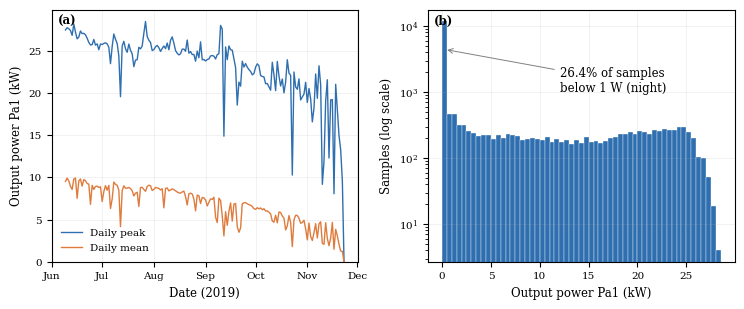

In [16]:
#Dataset overview (daily peak/mean and output-power distribution).
PLOT_DAILY = PLOT_DATA.set_index("timestamp")[TARGET].resample("D").agg(["max", "mean"])
PLOT_POWER_KW = PLOT_DATA[TARGET].to_numpy(dtype=float) / 1000.0
PLOT_BINS_KW = _plot_np.arange(0.0, _plot_np.ceil(_plot_np.nanmax(PLOT_POWER_KW) / 0.5) * 0.5 + 0.5, 0.5)
PLOT_NIGHT_PCT = 100.0 * _plot_np.mean(PLOT_DATA[TARGET].to_numpy(dtype=float) < 1.0)

fig, axes = _plot_plt.subplots(1, 2, figsize=(7.5, 3.15), gridspec_kw={"width_ratios": [1.0, 1.0]})
axes[0].plot(PLOT_DAILY.index, PLOT_DAILY["max"] / 1000.0, color=PLOT_BLUE, label="Daily peak")
axes[0].plot(PLOT_DAILY.index, PLOT_DAILY["mean"] / 1000.0, color=PLOT_ORANGE, label="Daily mean")
axes[0].set_ylabel("Output power Pa1 (kW)")
axes[0].set_xlabel("Date (2019)")
axes[0].set_ylim(bottom=0)
axes[0].xaxis.set_major_locator(_plot_mdates.MonthLocator())
axes[0].xaxis.set_major_formatter(_plot_mdates.DateFormatter("%b"))
axes[0].legend(frameon=False, loc="lower left")
axes[0].text(0.02, 0.98, "(a)", transform=axes[0].transAxes, va="top", fontweight="bold")

axes[1].hist(PLOT_POWER_KW, bins=PLOT_BINS_KW, color=PLOT_BLUE, edgecolor="white", linewidth=0.25, log=True)
axes[1].set_xlabel("Output power Pa1 (kW)")
axes[1].set_ylabel("Samples (log scale)")
axes[1].text(0.02, 0.98, "(b)", transform=axes[1].transAxes, va="top", fontweight="bold")
axes[1].annotate(
    f"{PLOT_NIGHT_PCT:.1f}% of samples\nbelow 1 W (night)",
    xy=(0.25, max(1.0, PLOT_DATA[TARGET].lt(1.0).sum() * 0.7)), xycoords=("data", "data"),
    xytext=(0.43, 0.72), textcoords="axes fraction",
    arrowprops={"arrowstyle": "->", "color": "0.5", "lw": 0.7}, ha="left", va="center"
)
for ax in axes:
    ax.grid(True, axis="both", alpha=0.22, linewidth=0.5)
save_paper_figure(fig, "fig2_dataset_overview")


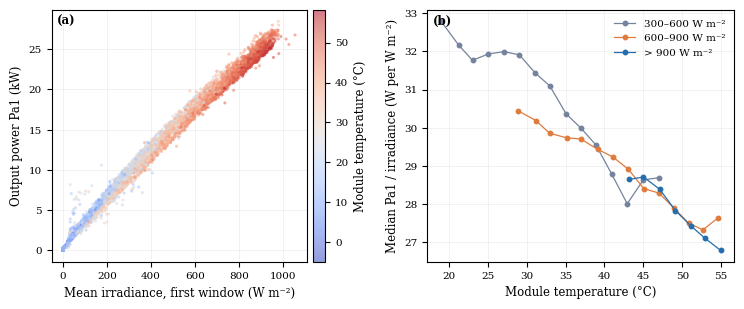

In [17]:
#Physical relationships motivating the engineered features.
PLOT_SCATTER = PLOT_DATA[[PLOT_IRR_COL, PLOT_TMOD_COL, TARGET]].dropna()
PLOT_SCATTER = PLOT_SCATTER.sample(n=min(8000, len(PLOT_SCATTER)), random_state=42)
PLOT_PHYS = PLOT_DATA[[PLOT_IRR_COL, PLOT_TMOD_COL, TARGET]].copy()
PLOT_PHYS = PLOT_PHYS.replace([_plot_np.inf, -_plot_np.inf], _plot_np.nan).dropna()
PLOT_PHYS = PLOT_PHYS[(PLOT_PHYS[PLOT_IRR_COL] > 300) & (PLOT_PHYS[TARGET] >= 0)]
PLOT_PHYS["ratio"] = PLOT_PHYS[TARGET] / PLOT_PHYS[PLOT_IRR_COL]
PLOT_PHYS["irradiance_class"] = _plot_pd.cut(
    PLOT_PHYS[PLOT_IRR_COL], bins=[300, 600, 900, _plot_np.inf],
    labels=["300–600 W m⁻²", "600–900 W m⁻²", "> 900 W m⁻²"], right=False
)
PLOT_PHYS["temp_bin"] = _plot_np.floor(PLOT_PHYS[PLOT_TMOD_COL] / 2.0) * 2.0 + 1.0
PLOT_MEDIANS = (
    PLOT_PHYS.groupby(["irradiance_class", "temp_bin"], observed=True)
    .agg(median_temp=(PLOT_TMOD_COL, "median"), median_ratio=("ratio", "median"), n=("ratio", "size"))
    .reset_index()
)
PLOT_MEDIANS = PLOT_MEDIANS[PLOT_MEDIANS["n"] >= 30]
PLOT_CLASS_STYLE = {
    "300–600 W m⁻²": (PLOT_SLATE, "o"),
    "600–900 W m⁻²": (PLOT_ORANGE, "o"),
    "> 900 W m⁻²": (PLOT_DARK_BLUE, "o"),
}

fig, axes = _plot_plt.subplots(1, 2, figsize=(7.5, 3.15), gridspec_kw={"width_ratios": [1.0, 1.0]})
sc = axes[0].scatter(
    PLOT_SCATTER[PLOT_IRR_COL], PLOT_SCATTER[TARGET] / 1000.0,
    c=PLOT_SCATTER[PLOT_TMOD_COL], cmap="coolwarm", s=5, alpha=0.55, linewidths=0,
)
axes[0].set_xlabel("Mean irradiance, first window (W m⁻²)")
axes[0].set_ylabel("Output power Pa1 (kW)")
axes[0].text(0.02, 0.98, "(a)", transform=axes[0].transAxes, va="top", fontweight="bold")
cbar = fig.colorbar(sc, ax=axes[0], pad=0.02)
cbar.set_label("Module temperature (°C)")

for class_name, (color, marker) in PLOT_CLASS_STYLE.items():
    group = PLOT_MEDIANS[PLOT_MEDIANS["irradiance_class"] == class_name].sort_values("median_temp")
    if not group.empty:
        axes[1].plot(group["median_temp"], group["median_ratio"], marker=marker, ms=3.2, lw=0.9,
                     color=color, label=class_name)
axes[1].set_xlabel("Module temperature (°C)")
axes[1].set_ylabel("Median Pa1 / irradiance (W per W m⁻²)")
axes[1].text(0.02, 0.98, "(b)", transform=axes[1].transAxes, va="top", fontweight="bold")
axes[1].legend(frameon=False, loc="upper right")
for ax in axes:
    ax.grid(True, alpha=0.22, linewidth=0.5)
save_paper_figure(fig, "fig3_physical_relationships")


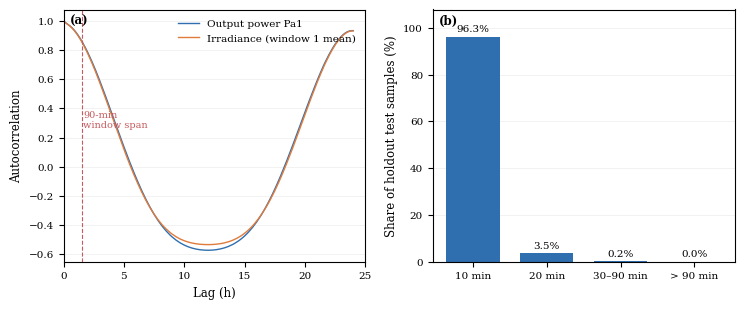

In [18]:
#Temporal dependence and test-to-training proximity.
PLOT_N_LAGS = 24 * 6  # 24 h on the original 10-minute grid.
PLOT_LAG_HOURS = _plot_np.arange(PLOT_N_LAGS + 1) / 6.0
PLOT_ACF_TARGET = PLOT_DATA[TARGET].astype(float).reset_index(drop=True)
PLOT_ACF_IRR = PLOT_DATA[PLOT_IRR_COL].astype(float).reset_index(drop=True)
PLOT_ACF_Y = _plot_np.array([PLOT_ACF_TARGET.autocorr(lag=int(k)) for k in range(PLOT_N_LAGS + 1)])
PLOT_ACF_R = _plot_np.array([PLOT_ACF_IRR.autocorr(lag=int(k)) for k in range(PLOT_N_LAGS + 1)])

PLOT_ALL_NS = _plot_np.sort(PLOT_DATA["timestamp"].astype("int64").to_numpy())
PLOT_TEST_NS = _plot_np.sort(PLOT_PREDICTIONS["timestamp"].astype("int64").to_numpy())
PLOT_TRAIN_NS = _plot_np.setdiff1d(PLOT_ALL_NS, PLOT_TEST_NS, assume_unique=False)
PLOT_POS = _plot_np.searchsorted(PLOT_TRAIN_NS, PLOT_TEST_NS)
PLOT_LEFT_POS = _plot_np.clip(PLOT_POS - 1, 0, len(PLOT_TRAIN_NS) - 1)
PLOT_RIGHT_POS = _plot_np.clip(PLOT_POS, 0, len(PLOT_TRAIN_NS) - 1)
PLOT_GAPS_MIN = _plot_np.minimum(
    _plot_np.abs(PLOT_TEST_NS - PLOT_TRAIN_NS[PLOT_LEFT_POS]),
    _plot_np.abs(PLOT_TRAIN_NS[PLOT_RIGHT_POS] - PLOT_TEST_NS),
) / 60_000_000_000.0
PLOT_GAP_COUNTS = _plot_np.array([
    _plot_np.sum(PLOT_GAPS_MIN <= 10),
    _plot_np.sum((PLOT_GAPS_MIN > 10) & (PLOT_GAPS_MIN <= 20)),
    _plot_np.sum((PLOT_GAPS_MIN > 20) & (PLOT_GAPS_MIN <= 90)),
    _plot_np.sum(PLOT_GAPS_MIN > 90),
], dtype=float)
PLOT_GAP_PCT = 100.0 * PLOT_GAP_COUNTS / max(1, len(PLOT_GAPS_MIN))

fig, axes = _plot_plt.subplots(1, 2, figsize=(7.5, 3.15), gridspec_kw={"width_ratios": [1.0, 1.0]})
axes[0].plot(PLOT_LAG_HOURS, PLOT_ACF_Y, color=PLOT_BLUE, label="Output power Pa1")
axes[0].plot(PLOT_LAG_HOURS, PLOT_ACF_R, color=PLOT_ORANGE, label="Irradiance (window 1 mean)")
axes[0].axvline(1.5, color="#c55b60", linestyle="--", lw=0.8)
axes[0].text(1.65, 0.27, "90-min\nwindow span", color="#c55b60", fontsize=7)
axes[0].set_xlabel("Lag (h)")
axes[0].set_ylabel("Autocorrelation")
axes[0].set_xlim(0, 25)
axes[0].text(0.02, 0.98, "(a)", transform=axes[0].transAxes, va="top", fontweight="bold")
axes[0].legend(frameon=False, loc="upper right")

PLOT_GAP_LABELS = ["10 min", "20 min", "30–90 min", "> 90 min"]
bar_positions = _plot_np.arange(len(PLOT_GAP_LABELS))
axes[1].bar(bar_positions, PLOT_GAP_PCT, color=PLOT_BLUE, width=0.72)
axes[1].set_xticks(bar_positions, PLOT_GAP_LABELS)
axes[1].set_ylabel("Share of holdout test samples (%)")
axes[1].set_ylim(0, max(105, float(PLOT_GAP_PCT.max() * 1.12)))
axes[1].text(0.02, 0.98, "(b)", transform=axes[1].transAxes, va="top", fontweight="bold")
for x, val in zip(bar_positions, PLOT_GAP_PCT):
    axes[1].text(x, val + 1.2, f"{val:.1f}%", ha="center", va="bottom", fontsize=7.5)
for ax in axes:
    ax.grid(True, axis="y", alpha=0.22, linewidth=0.5)
    ax.set_axisbelow(True)
save_paper_figure(fig, "fig4_temporal_dependence")


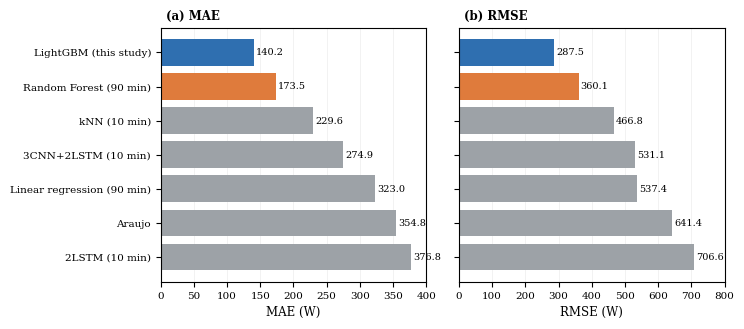

In [19]:
#Benchmark MAE and RMSE comparison (published values retained).
PLOT_BENCHMARK_NAMES = [
    "LightGBM (this study)",
    "Random Forest (90 min)",
    "kNN (10 min)",
    "3CNN+2LSTM (10 min)",
    "Linear regression (90 min)",
    "Araujo",
    "2LSTM (10 min)",
]
PLOT_BENCHMARK_MAE = [
    float(PLOT_SCORE["mae_w"]), 173.47, 229.6, 274.87, 323.0, 354.81, 376.8
]
PLOT_BENCHMARK_RMSE = [
    float(PLOT_SCORE["rmse_w"]), 360.13, 466.8, 531.08, 537.4, 641.36, 706.6
]
PLOT_BENCHMARK_COLORS = [PLOT_BLUE, PLOT_ORANGE] + [PLOT_GRAY] * (len(PLOT_BENCHMARK_NAMES) - 2)
PLOT_Y_POS = _plot_np.arange(len(PLOT_BENCHMARK_NAMES))

fig, axes = _plot_plt.subplots(1, 2, figsize=(7.5, 3.35), sharey=True)
for ax, vals, metric, limit in [
    (axes[0], PLOT_BENCHMARK_MAE, "MAE (W)", 400),
    (axes[1], PLOT_BENCHMARK_RMSE, "RMSE (W)", 800),
]:
    ax.barh(PLOT_Y_POS, vals, color=PLOT_BENCHMARK_COLORS, height=0.78)
    ax.set_xlabel(metric)
    ax.set_xlim(0, limit)
    ax.set_yticks(PLOT_Y_POS, PLOT_BENCHMARK_NAMES)
    ax.grid(True, axis="x", alpha=0.22, linewidth=0.5)
    ax.set_axisbelow(True)
    for y_pos, val in zip(PLOT_Y_POS, vals):
        ax.text(val + limit * 0.008, y_pos, f"{val:.1f}", va="center", ha="left", fontsize=7)
axes[0].invert_yaxis()  # shared y-axis: invert once so LightGBM is the top row.
axes[0].text(0.02, 1.02, "(a) MAE", transform=axes[0].transAxes, va="bottom", fontweight="bold")
axes[1].text(0.02, 1.02, "(b) RMSE", transform=axes[1].transAxes, va="bottom", fontweight="bold")
fig.subplots_adjust(wspace=0.28)
save_paper_figure(fig, "fig5_benchmark_comparison")


/tmp/ipykernel_8711/378614714.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


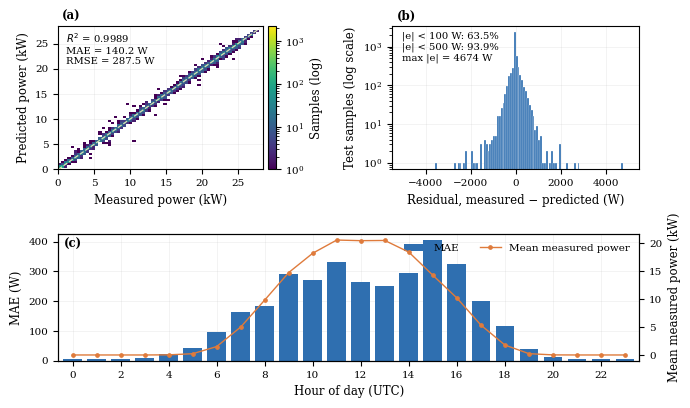

In [20]:
#Held-out prediction performance, residuals, and hourly errors.
PLOT_HOLDOUT = PLOT_PREDICTIONS.copy()
PLOT_HOLDOUT["prediction_W"] = PLOT_HOLDOUT["selected_LightGBM_prediction_W"]
PLOT_HOLDOUT["residual_W"] = PLOT_HOLDOUT["actual_Pa1_W"] - PLOT_HOLDOUT["prediction_W"]
PLOT_HOLDOUT["absolute_error_W"] = _plot_np.abs(PLOT_HOLDOUT["residual_W"])
PLOT_HOLDOUT["actual_kW"] = PLOT_HOLDOUT["actual_Pa1_W"] / 1000.0
PLOT_HOLDOUT["prediction_kW"] = PLOT_HOLDOUT["prediction_W"] / 1000.0
PLOT_FRAC_100 = 100.0 * (PLOT_HOLDOUT["absolute_error_W"] < 100).mean()
PLOT_FRAC_500 = 100.0 * (PLOT_HOLDOUT["absolute_error_W"] < 500).mean()
PLOT_MAX_ABS = float(PLOT_HOLDOUT["absolute_error_W"].max())

fig = _plot_plt.figure(figsize=(7.5, 4.35))
gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 0.88], hspace=0.48, wspace=0.35)
ax_a = fig.add_subplot(gs[0, 0])
ax_b = fig.add_subplot(gs[0, 1])
ax_c = fig.add_subplot(gs[1, :])

hist = ax_a.hist2d(
    PLOT_HOLDOUT["actual_kW"], PLOT_HOLDOUT["prediction_kW"],
    bins=65, norm=_PlotLogNorm(), cmap="viridis", cmin=1,
)
max_kw = max(float(PLOT_HOLDOUT["actual_kW"].max()), float(PLOT_HOLDOUT["prediction_kW"].max()))
ax_a.plot([0, max_kw], [0, max_kw], color="#d7e4b2", linestyle="--", lw=0.9)
ax_a.set_xlim(left=0, right=max_kw * 1.02)
ax_a.set_ylim(bottom=0, top=max_kw * 1.02)
ax_a.set_xlabel("Measured power (kW)")
ax_a.set_ylabel("Predicted power (kW)")
ax_a.text(0.04, 0.96,
          f"$R^2$ = {float(PLOT_SCORE['r2']):.4f}\nMAE = {float(PLOT_SCORE['mae_w']):.1f} W\nRMSE = {float(PLOT_SCORE['rmse_w']):.1f} W",
          transform=ax_a.transAxes, ha="left", va="top", fontsize=7.2)
ax_a.text(0.02, 1.02, "(a)", transform=ax_a.transAxes, va="bottom", fontweight="bold")
cbar = fig.colorbar(hist[3], ax=ax_a, pad=0.02)
cbar.set_label("Samples (log)")

resid_bins = _plot_np.linspace(-5000, 5000, 121)
ax_b.hist(PLOT_HOLDOUT["residual_W"], bins=resid_bins, color=PLOT_BLUE, edgecolor="white", linewidth=0.2, log=True)
ax_b.set_xlabel("Residual, measured − predicted (W)")
ax_b.set_ylabel("Test samples (log scale)")
ax_b.text(0.04, 0.96,
          f"|e| < 100 W: {PLOT_FRAC_100:.1f}%\n|e| < 500 W: {PLOT_FRAC_500:.1f}%\nmax |e| = {PLOT_MAX_ABS:.0f} W",
          transform=ax_b.transAxes, ha="left", va="top", fontsize=7.2)
ax_b.text(0.02, 1.02, "(b)", transform=ax_b.transAxes, va="bottom", fontweight="bold")

PLOT_HOLDOUT["hour_utc"] = PLOT_HOLDOUT["timestamp"].dt.hour
PLOT_HOURLY = PLOT_HOLDOUT.groupby("hour_utc").agg(
    mae_W=("absolute_error_W", "mean"), mean_power_kW=("actual_kW", "mean")
).reindex(range(24))
ax_c.bar(PLOT_HOURLY.index, PLOT_HOURLY["mae_W"], color=PLOT_BLUE, width=0.78, label="MAE")
ax_c.set_xlabel("Hour of day (UTC)")
ax_c.set_ylabel("MAE (W)")
ax_c.set_xticks(range(0, 24, 2))
ax_c.set_xlim(-0.6, 23.6)
ax_c2 = ax_c.twinx()
ax_c2.plot(PLOT_HOURLY.index, PLOT_HOURLY["mean_power_kW"], color=PLOT_ORANGE, marker="o", ms=2.4, lw=1.0,
           label="Mean measured power")
ax_c2.set_ylabel("Mean measured power (kW)")
ax_c.text(0.01, 0.97, "(c)", transform=ax_c.transAxes, va="top", fontweight="bold")
handles1, labels1 = ax_c.get_legend_handles_labels()
handles2, labels2 = ax_c2.get_legend_handles_labels()
ax_c.legend(handles1 + handles2, labels1 + labels2, frameon=False, loc="upper right", ncol=2)
for ax in (ax_a, ax_b, ax_c):
    ax.grid(True, alpha=0.2, linewidth=0.5)
    ax.set_axisbelow(True)
save_paper_figure(fig, "fig6_holdout_performance")


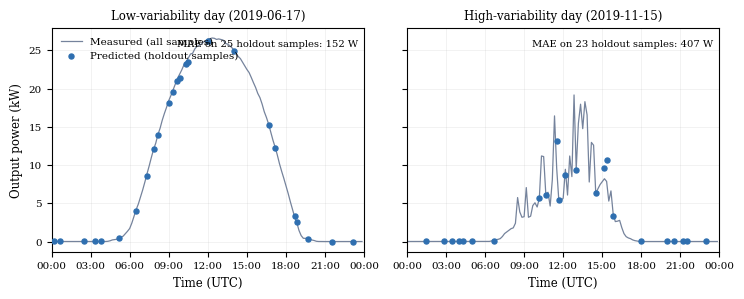

In [21]:
#Two example days showing measured power and holdout predictions.
PLOT_EXAMPLE_DAYS = [
    ("2019-06-17", "Low-variability day"),
    ("2019-11-15", "High-variability day"),
]
fig, axes = _plot_plt.subplots(1, 2, figsize=(7.5, 3.05), sharey=True)
for ax, (day, label) in zip(axes, PLOT_EXAMPLE_DAYS):
    PLOT_DAY = PLOT_FULL[PLOT_FULL["timestamp"].dt.strftime("%Y-%m-%d") == day].copy()
    PLOT_DAY_TEST = PLOT_DAY[PLOT_DAY["selected_LightGBM_prediction_W"].notna()].copy()
    PLOT_DAY_MAE = float(_plot_np.mean(_plot_np.abs(
        PLOT_DAY_TEST[TARGET].to_numpy(dtype=float) - PLOT_DAY_TEST["selected_LightGBM_prediction_W"].to_numpy(dtype=float)
    ))) if len(PLOT_DAY_TEST) else float("nan")
    ax.plot(PLOT_DAY["timestamp"], PLOT_DAY[TARGET] / 1000.0, color=PLOT_SLATE, lw=0.9,
            label="Measured (all samples)")
    ax.scatter(PLOT_DAY_TEST["timestamp"], PLOT_DAY_TEST["selected_LightGBM_prediction_W"] / 1000.0,
               color=PLOT_BLUE, s=13, zorder=3, label="Predicted (holdout samples)")
    ax.set_title(f"{label} ({day})", fontsize=8.5)
    ax.text(0.98, 0.95, f"MAE on {len(PLOT_DAY_TEST)} holdout samples: {PLOT_DAY_MAE:.0f} W",
            transform=ax.transAxes, va="top", ha="right", fontsize=7.2)
    ax.set_xlabel("Time (UTC)")
    ax.xaxis.set_major_locator(_plot_mdates.HourLocator(byhour=[0, 3, 6, 9, 12, 15, 18, 21]))
    ax.xaxis.set_major_formatter(_plot_mdates.DateFormatter("%H:%M", tz=_plot_pd.Timestamp(day, tz="UTC").tzinfo))
    ax.set_xlim(_plot_pd.Timestamp(day, tz="UTC"), _plot_pd.Timestamp(day, tz="UTC") + _plot_pd.Timedelta(days=1))
    ax.grid(True, alpha=0.22, linewidth=0.5)
axes[0].set_ylabel("Output power (kW)")
axes[0].legend(frameon=False, loc="upper left")
save_paper_figure(fig, "fig7_example_days")


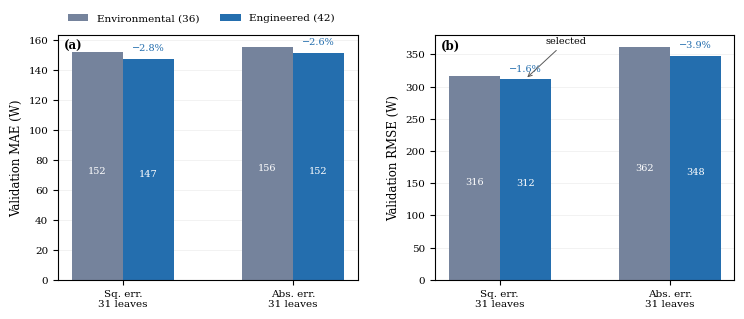

In [22]:
#Validation-subset MAE/RMSE for the four original LightGBM candidates.
PLOT_VAL = PLOT_VALIDATION.copy()
PLOT_VAL["feature_label"] = PLOT_VAL["schema"].map({"env_only": "Environmental (36)", "env_engineered": "Engineered (42)"})
PLOT_VAL["objective_label"] = PLOT_VAL["config_name"].map({"LGBM_leaf31": "Sq. err.", "LGBM_l1_leaf31": "Abs. err."})
PLOT_VAL["feature_order"] = PLOT_VAL["schema"].map({"env_only": 0, "env_engineered": 1})
PLOT_VAL["objective_order"] = PLOT_VAL["config_name"].map({"LGBM_leaf31": 0, "LGBM_l1_leaf31": 1})
PLOT_SELECTED = str(PLOT_RECIPE["selected_candidate"])
PLOT_OBJ_LABELS = ["Sq. err.\n31 leaves", "Abs. err.\n31 leaves"]
PLOT_METRICS = [("val_mae_w", "Validation MAE (W)", 0), ("val_rmse_w", "Validation RMSE (W)", 1)]
fig, axes = _plot_plt.subplots(1, 2, figsize=(7.5, 3.25))
width = 0.30
x_centers = _plot_np.array([0.0, 1.0])
for ax, (metric, ylabel, panel) in zip(axes, PLOT_METRICS):
    for feature_order, feature_label, color, offset in [
        (0, "Environmental (36)", PLOT_SLATE, -width / 2),
        (1, "Engineered (42)", PLOT_DARK_BLUE, width / 2),
    ]:
        vals = []
        for obj_order in [0, 1]:
            row = PLOT_VAL[(PLOT_VAL["feature_order"] == feature_order) & (PLOT_VAL["objective_order"] == obj_order)]
            vals.append(float(row.iloc[0][metric]))
        bars = ax.bar(x_centers + offset, vals, width=width, color=color, label=feature_label)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, max(val * 0.48, 1), f"{val:.0f}",
                    color="white", ha="center", va="center", fontsize=7.0)
    ax.set_xticks(x_centers, PLOT_OBJ_LABELS)
    ax.set_ylabel(ylabel)
    ax.grid(True, axis="y", alpha=0.22, linewidth=0.5)
    ax.set_axisbelow(True)
    ax.text(0.02, 0.98, "(a)" if panel == 0 else "(b)", transform=ax.transAxes, va="top", fontweight="bold")
    for obj_order, center in enumerate(x_centers):
        subset = PLOT_VAL[PLOT_VAL["objective_order"] == obj_order].set_index("schema")
        old = float(subset.loc["env_only", metric])
        new = float(subset.loc["env_engineered", metric])
        reduction = 100.0 * (old - new) / old if old else 0.0
        new_bar_x = center + width / 2
        ax.text(new_bar_x, new + (ax.get_ylim()[1] * 0.025), f"−{abs(reduction):.1f}%" if reduction >= 0 else f"+{abs(reduction):.1f}%",
                color=PLOT_DARK_BLUE, ha="center", va="bottom", fontsize=7.0)
    if metric == "val_rmse_w":
        selected_row = PLOT_VAL[PLOT_VAL["candidate"] == PLOT_SELECTED]
        if not selected_row.empty:
            selected_obj = int(selected_row.iloc[0]["objective_order"])
            selected_feature = int(selected_row.iloc[0]["feature_order"])
            sx = x_centers[selected_obj] + (width / 2 if selected_feature == 1 else -width / 2)
            sy = float(selected_row.iloc[0][metric])
            ax.annotate("selected", xy=(sx, sy), xytext=(sx + 0.12, sy + 55),
                        arrowprops={"arrowstyle": "->", "lw": 0.7, "color": "0.35"}, fontsize=7.0, ha="left")
axes[0].legend(frameon=False, loc="lower left", bbox_to_anchor=(0.0, 1.01), ncol=2)
for ax in axes:
    ax.set_ylim(bottom=0)
save_paper_figure(fig, "fig8_validation_search")


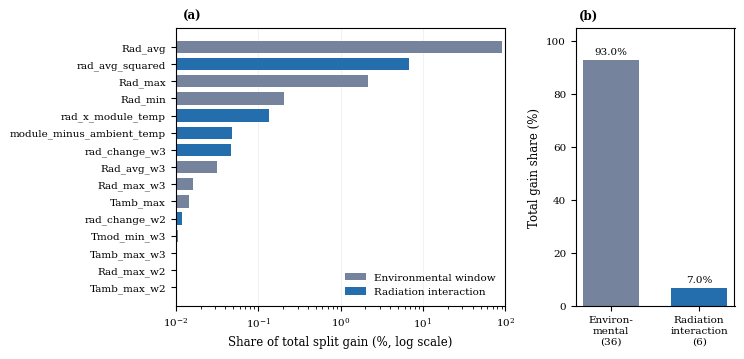

In [23]:
#Top feature importances and total gain by feature group.
PLOT_IMP = PLOT_IMPORTANCE.copy()
PLOT_IMP["importance_gain"] = _plot_pd.to_numeric(PLOT_IMP["importance_gain"], errors="coerce").fillna(0.0)
PLOT_TOTAL_GAIN = float(PLOT_IMP["importance_gain"].sum())
if PLOT_TOTAL_GAIN <= 0:
    raise ValueError("The saved LightGBM gain importances sum to zero; cannot plot Figure 9.")
PLOT_IMP["gain_share_pct"] = 100.0 * PLOT_IMP["importance_gain"] / PLOT_TOTAL_GAIN
PLOT_IMP["is_engineered"] = PLOT_IMP["feature"].astype(str).str.startswith("engineered_")
PLOT_FEATURE_LABELS = {
    "engineered_rad_squared": "rad_avg_squared",
    "engineered_rad_x_module_temp": "rad_x_module_temp",
    "engineered_rad_x_ambient_temp": "rad_x_ambient_temp",
    "engineered_module_minus_ambient_temp": "module_minus_ambient_temp",
    "engineered_rad_delta_w2": "rad_change_w2",
    "engineered_rad_delta_w3": "rad_change_w3",
}
PLOT_IMP["display_feature"] = PLOT_IMP["feature"].map(PLOT_FEATURE_LABELS).fillna(PLOT_IMP["feature"])
PLOT_TOP = PLOT_IMP.sort_values("gain_share_pct", ascending=False).head(15).sort_values("gain_share_pct", ascending=True)
PLOT_ENV_GAIN = float(PLOT_IMP.loc[~PLOT_IMP["is_engineered"], "importance_gain"].sum())
PLOT_ENG_GAIN = float(PLOT_IMP.loc[PLOT_IMP["is_engineered"], "importance_gain"].sum())
PLOT_GROUP_PCT = _plot_np.array([PLOT_ENV_GAIN, PLOT_ENG_GAIN]) * 100.0 / PLOT_TOTAL_GAIN

fig, axes = _plot_plt.subplots(1, 2, figsize=(7.5, 3.65), gridspec_kw={"width_ratios": [1.35, 0.65]})
PLOT_TOP_COLORS = [PLOT_DARK_BLUE if val else PLOT_SLATE for val in PLOT_TOP["is_engineered"]]
axes[0].barh(PLOT_TOP["display_feature"], PLOT_TOP["gain_share_pct"], color=PLOT_TOP_COLORS, height=0.72)
axes[0].set_xscale("log")
axes[0].set_xlim(1e-2, 1e2)
axes[0].set_xlabel("Share of total split gain (%, log scale)")
axes[0].text(0.02, 1.02, "(a)", transform=axes[0].transAxes, va="bottom", fontweight="bold")
axes[0].grid(True, axis="x", alpha=0.22, linewidth=0.5)
axes[0].set_axisbelow(True)

axes[1].bar([0, 1], PLOT_GROUP_PCT, color=[PLOT_SLATE, PLOT_DARK_BLUE], width=0.64)
axes[1].set_xticks([0, 1], ["Environ-\nmental\n(36)", "Radiation\ninteraction\n(6)"])
axes[1].set_ylabel("Total gain share (%)")
axes[1].set_ylim(0, 105)
axes[1].text(0.02, 1.02, "(b)", transform=axes[1].transAxes, va="bottom", fontweight="bold")
for x, val in enumerate(PLOT_GROUP_PCT):
    axes[1].text(x, val + 1.2, f"{val:.1f}%", ha="center", va="bottom", fontsize=7.5)
axes[0].patch.set_alpha(0)
from matplotlib.patches import Patch as _PlotPatch
axes[0].legend(handles=[_PlotPatch(facecolor=PLOT_SLATE, label="Environmental window"),
                        _PlotPatch(facecolor=PLOT_DARK_BLUE, label="Radiation interaction")],
               frameon=False, loc="lower right")
save_paper_figure(fig, "fig9_feature_importance")
